# Two Salt Lakes, Two Stories: Lake Urmia (Iran) and Lake Van (Turkiye), 1990–2025

Lake Urmia and Lake Van sit about 150 km apart on the same high plateau. Both are large closed-basin lakes: no river
leaves them, so their size is set by the balance between what flows in and what evaporates. Lake Urmia, once the
largest lake in the Middle East, lost most of its water in the 2000s and 2010s, while Lake Van has stayed close to its
long-term size. In this notebook I put the two side by side.

**What it does**

1. Finds each lake's outline from the JRC Global Surface Water map (the largest extent water has reached since 1984).
2. Measures the **water area twice a year** (spring high and late-summer low) from Landsat 5, 7, 8 and 9, with clouds
   removed and a water threshold chosen automatically for every image (Otsu's method on MNDWI).
3. Compares the lakes: change since the late 1990s, trends, the lowest year, and Lake Urmia since its restoration
   programme began in 2013.
4. Looks at **rain and temperature** over each lake's whole drainage basin (ERA5-Land), to see how much climate alone explains.
5. Checks my areas against the **JRC yearly water maps**, and, if you add them, compares with **satellite water levels**
   (DAHITI altimetry) to draw each lake's level–area curve.

**Why this is new:** published studies have measured each lake with Earth Engine, but I could not find shared code
that tracks both lakes together, or that combines area with water level, so this notebook fills that gap.

## 1. Setup

Every Earth Engine result is saved to `outputs/urmia_van/` as soon as it arrives. The first run makes a few hundred small
requests (expect 20–40 minutes); after that, **Restart & Run All** takes seconds, and an interrupted run continues where it stopped.

In [1]:
import os, io, json, time
import ee
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import requests
from PIL import Image
from scipy import stats
ee.Initialize(project="")   # <-- replace with your Earth Engine project ID

plt.rcParams.update({"figure.dpi": 120, "savefig.dpi": 300, "font.size": 11})

C:\Users\moham\anaconda3\Lib\site-packages\google\api_core\_python_version_support.py:254: FutureWarning: You are using a Python version (3.11.18) which Google will stop supporting in new releases of google.api_core once it reaches its end of life (2027-10-24). Please upgrade to the latest Python version, or at least Python 3.12, to continue receiving updates for google.api_core past that date.
  warnings.warn(message, FutureWarning)


## 2. The lakes and the settings

In [2]:
FIG_DIR, OUT_DIR = "figures/urmia_van", "outputs/urmia_van"
MAP_DIR = f"{OUT_DIR}/map_images"
LEVEL_DIR = "data/lake_levels"            # optional altimetry files (see Section 9)
for d in (FIG_DIR, OUT_DIR, MAP_DIR, LEVEL_DIR):
    os.makedirs(d, exist_ok=True)

# For each lake: a box that contains it, and a point in open water used to pick the lake out of the water map
LAKES = {
    "Lake Urmia": {"bbox": [44.95, 37.05, 46.15, 38.30], "center": [45.30, 37.70], "color": "#d95f0e"},
    "Lake Van":   {"bbox": [42.25, 38.25, 43.47, 39.05], "center": [42.90, 38.65], "color": "#08519c"},
}
START_YEAR, END_YEAR = 1990, 2025
SEASONS = {"spring": (4, 6), "late summer": (8, 10)}   # months: near the yearly high and the yearly low
REFERENCE = (1995, 1999)       # the "before" period changes are measured against
RESTORATION_START = 2013       # Lake Urmia Restoration Programme
MAX_CLOUD = 60                 # scene-level cloud filter (%); clouds are also removed pixel by pixel
MIN_COVERAGE = 0.90            # use a season only if at least 90% of the lake zone could be seen
AREA_SCALE, HIST_SCALE = 60, 120   # metres for the area sum and for the histogram used to pick the threshold
FALLBACK_THRESHOLD = 0.0       # used if a histogram has no clear water/land split
SHORE_BUFFER = 1000            # metres added around each lake outline, so a growing lake is not cut off

## 3. Each lake's outline

From the JRC map of the largest water extent since 1984, I turn the water pixels into polygons and keep the one that
contains the lake's open-water point. Small lakes nearby (for example Lake Erçek east of Van) are left out. The outlines
are saved, so this only runs once.

In [3]:
ZONES_JSON = f"{OUT_DIR}/lake_zones.json"
zones = json.load(open(ZONES_JSON)) if os.path.exists(ZONES_JSON) else {}

for name, lake in LAKES.items():
    if name in zones:
        continue
    box = ee.Geometry.Rectangle(lake["bbox"])
    water = ee.Image("JRC/GSW1_4/GlobalSurfaceWater").select("max_extent").eq(1).selfMask().clip(box)
    polygons = water.reduceToVectors(geometry=box, scale=90, geometryType="polygon", eightConnected=True,
                                     maxPixels=1e10, tileScale=4)
    outline = ee.Feature(polygons.filterBounds(ee.Geometry.Point(lake["center"])).first()).geometry().simplify(300)
    zones[name] = {"geometry": outline.getInfo(), "area_km2": outline.area(100).divide(1e6).getInfo()}
    json.dump(zones, open(ZONES_JSON, "w"))
    print(f"{name}: largest extent since 1984 ≈ {zones[name]['area_km2']:,.0f} km²")

zone_geom = {name: ee.Geometry(zones[name]["geometry"]).buffer(SHORE_BUFFER) for name in LAKES}
zone_km2 = {name: zone_geom[name].area(100).divide(1e6).getInfo() for name in LAKES}
print({k: round(v) for k, v in zone_km2.items()})

Lake Urmia: largest extent since 1984 ≈ 5,810 km²
Lake Van: largest extent since 1984 ≈ 3,468 km²
{'Lake Urmia': 6566, 'Lake Van': 3939}


## 4. Landsat 5, 7, 8 and 9 as one collection

The four sensors use different band numbers, so I rename them to common names (green, red, blue, SWIR1) and apply the
Collection 2 scaling. Clouds, cloud shadows and cirrus are removed with the `QA_PIXEL` band.

**MNDWI** = (green − SWIR1) / (green + SWIR1). Water absorbs shortwave infrared strongly, so it stands out even when it is
muddy, salty or reddish (Lake Urmia's water often turns red from salt-loving algae).

In [4]:
def make_prep(green, red, blue, swir1):
    def prep(img):
        clear = img.select("QA_PIXEL").bitwiseAnd(0b11111).eq(0)   # bits 0-4: fill, dilated cloud, cirrus, cloud, shadow
        sr = (img.select([green, red, blue, swir1], ["green", "red", "blue", "swir1"])
                 .multiply(2.75e-05).add(-0.2))
        mndwi = sr.normalizedDifference(["green", "swir1"]).rename("mndwi")
        return sr.addBands(mndwi).updateMask(clear).copyProperties(img, ["system:time_start"])
    return prep

def landsat_collection(region):
    def load(cid, prep):
        return (ee.ImageCollection(cid).filterBounds(region).filter(ee.Filter.lt("CLOUD_COVER", MAX_CLOUD)).map(prep))
    tm = make_prep("SR_B2", "SR_B3", "SR_B1", "SR_B5")      # Landsat 5 and 7
    oli = make_prep("SR_B3", "SR_B4", "SR_B2", "SR_B6")     # Landsat 8 and 9
    return (load("LANDSAT/LT05/C02/T1_L2", tm).merge(load("LANDSAT/LE07/C02/T1_L2", tm))
              .merge(load("LANDSAT/LC08/C02/T1_L2", oli)).merge(load("LANDSAT/LC09/C02/T1_L2", oli)))

landsat = {name: landsat_collection(zone_geom[name]) for name in LAKES}

def season_composite(name, year, months):
    col = (landsat[name].filterDate(f"{year}-01-01", f"{year + 1}-01-01")
                        .filter(ee.Filter.calendarRange(months[0], months[1], "month")))
    return col.median(), col.size()

## 5. Water area for every lake, year and season

For each season I take the median of all clear Landsat images, read the MNDWI histogram around the lake, let Otsu's
method pick the water threshold, and add up the water area inside the lake outline. Each result is saved immediately.

In [5]:
AREA_CSV = f"{OUT_DIR}/lake_area_by_season.csv"
px = ee.Image.pixelArea().divide(1e6)

def otsu(centers, counts):
    centers, counts = np.asarray(centers, float), np.asarray(counts, float)
    w0 = np.cumsum(counts); w1 = w0[-1] - w0
    m0 = np.cumsum(counts * centers)
    mu0 = np.divide(m0, w0, out=np.zeros_like(m0), where=w0 > 0)
    mu1 = np.divide(m0[-1] - m0, w1, out=np.zeros_like(m0), where=w1 > 0)
    between = (w0 * w1 * (mu0 - mu1) ** 2)[:-1]
    i = int(np.argmax(between))
    return float((centers[i] + centers[i + 1]) / 2)

def with_retries(fn, tries=3):
    for attempt in range(tries):
        try:
            return fn()
        except ee.EEException as e:
            if attempt == tries - 1:
                raise
            print(f"   retrying after: {str(e)[:70]}")
            time.sleep(10 * (attempt + 1))

done = pd.read_csv(AREA_CSV) if os.path.exists(AREA_CSV) else pd.DataFrame(
    columns=["lake", "season", "year", "images", "threshold", "water_km2", "seen_km2"])
done_keys = set(zip(done["lake"], done["season"], done["year"].astype(int))) if len(done) else set()

for name in LAKES:
    for season, months in SEASONS.items():
        for year in range(START_YEAR, END_YEAR + 1):
            if (name, season, year) in done_keys:
                continue
            comp, n_images = season_composite(name, year, months)
            mndwi = comp.select("mndwi")
            info = with_retries(lambda: ee.Dictionary({
                "n": n_images,
                "hist": mndwi.reduceRegion(ee.Reducer.histogram(maxBuckets=256), zone_geom[name].buffer(3000),
                                           HIST_SCALE, maxPixels=1e10, tileScale=4).get("mndwi"),
            }).getInfo())
            row = {"lake": name, "season": season, "year": year, "images": info["n"],
                   "threshold": np.nan, "water_km2": np.nan, "seen_km2": 0.0}
            if info["n"] and info.get("hist"):
                t = otsu(info["hist"]["bucketMeans"], info["hist"]["histogram"])
                t = t if -0.4 <= t <= 0.4 else FALLBACK_THRESHOLD
                sums = with_retries(lambda: ee.Image.cat(
                    mndwi.gt(t).selfMask().multiply(px).rename("water"),
                    mndwi.mask().gt(0).selfMask().multiply(px).rename("seen"),
                ).reduceRegion(ee.Reducer.sum(), zone_geom[name], AREA_SCALE, maxPixels=1e11, tileScale=8).getInfo())
                row.update({"threshold": t, "water_km2": sums.get("water") or 0.0, "seen_km2": sums.get("seen") or 0.0})
            done = pd.concat([done, pd.DataFrame([row])], ignore_index=True)
            done.to_csv(AREA_CSV, index=False)
            print(f"{name:11s} {season:11s} {year}: {row['images']:>3} images, water {row['water_km2'] or 0:8,.0f} km²")

areas = done.astype({"year": int, "images": int, "water_km2": float, "seen_km2": float})
areas["coverage"] = areas.apply(lambda r: r["seen_km2"] / zone_km2[r["lake"]], axis=1)
good = areas[(areas["coverage"] >= MIN_COVERAGE) & areas["water_km2"].notna()].copy()
print(f"Seasons with at least {MIN_COVERAGE:.0%} of the lake seen: {len(good)} of {len(areas)}")

C:\Users\moham\AppData\Local\Temp\ipykernel_7372\2290347017.py:50: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  done = pd.concat([done, pd.DataFrame([row])], ignore_index=True)


Lake Urmia  spring      1990:  10 images, water    5,359 km²
Lake Urmia  spring      1991:   7 images, water    5,205 km²
Lake Urmia  spring      1992:  15 images, water    5,427 km²
Lake Urmia  spring      1993:   7 images, water    5,721 km²
Lake Urmia  spring      1994:  10 images, water    5,970 km²
Lake Urmia  spring      1995:  18 images, water    6,028 km²
Lake Urmia  spring      1996:  15 images, water    5,981 km²
Lake Urmia  spring      1997:  14 images, water    5,837 km²
Lake Urmia  spring      1998:  12 images, water    5,790 km²
Lake Urmia  spring      1999:  18 images, water    5,431 km²
Lake Urmia  spring      2000:  20 images, water    5,001 km²
Lake Urmia  spring      2001:  26 images, water    4,685 km²
Lake Urmia  spring      2002:  16 images, water    4,664 km²
Lake Urmia  spring      2003:   7 images, water    4,894 km²
Lake Urmia  spring      2004:  16 images, water    4,647 km²
Lake Urmia  spring      2005:  21 images, water    4,594 km²
Lake Urmia  spring      

## 6. How the two lakes compare

In [6]:
def lake_summary(g):
    s = g.set_index("year")["water_km2"]
    ref = s.loc[REFERENCE[0]:REFERENCE[1]].mean()
    years = s.index.to_numpy(dtype=float)
    slope = stats.theilslopes(s.values, years)[0]
    p = stats.kendalltau(years, s.values)[1]
    after = s.loc[RESTORATION_START:]
    slope_after = stats.theilslopes(after.values, after.index.to_numpy(dtype=float))[0] if len(after) > 3 else np.nan
    return pd.Series({
        f"Mean area {REFERENCE[0]}–{REFERENCE[1]} (km²)": ref,
        "Smallest area (km²)": s.min(), "Year of smallest area": int(s.idxmin()),
        f"Latest area (km², {int(s.index.max())})": s.iloc[-1],
        "Latest vs. reference (%)": 100 * (s.iloc[-1] / ref - 1) if ref else np.nan,
        "Smallest vs. reference (%)": 100 * (s.min() / ref - 1) if ref else np.nan,
        f"Trend {int(years.min())}–{int(years.max())} (km²/yr)": slope, "Trend p-value (Mann–Kendall)": p,
        f"Trend since {RESTORATION_START} (km²/yr)": slope_after,
    })

summary = good.groupby(["lake", "season"]).apply(lake_summary).T
summary.round(2).to_csv(f"{OUT_DIR}/lake_comparison_summary.csv")
summary.round(1)

lake                          Lake Urmia            Lake Van        
season                       late summer  spring late summer  spring
Mean area 1995–1999 (km²)         5647.9  5813.2      3484.6  3487.5
Smallest area (km²)               2476.7  2621.5      3220.3  3415.1
Year of smallest area             2025.0  2025.0      2003.0  2025.0
Latest area (km², 2025)           2476.7  2621.5      3429.8  3415.1
Latest vs. reference (%)           -56.1   -54.9        -1.6    -2.1
Smallest vs. reference (%)         -56.1   -54.9        -7.6    -2.1
Trend 1990–2025 (km²/yr)          -101.4  -102.5        -0.9    -1.0
Trend p-value (Mann–Kendall)         0.0     0.0         0.0     0.0
Trend since 2013 (km²/yr)          -17.6   -16.7        -2.4    -2.6

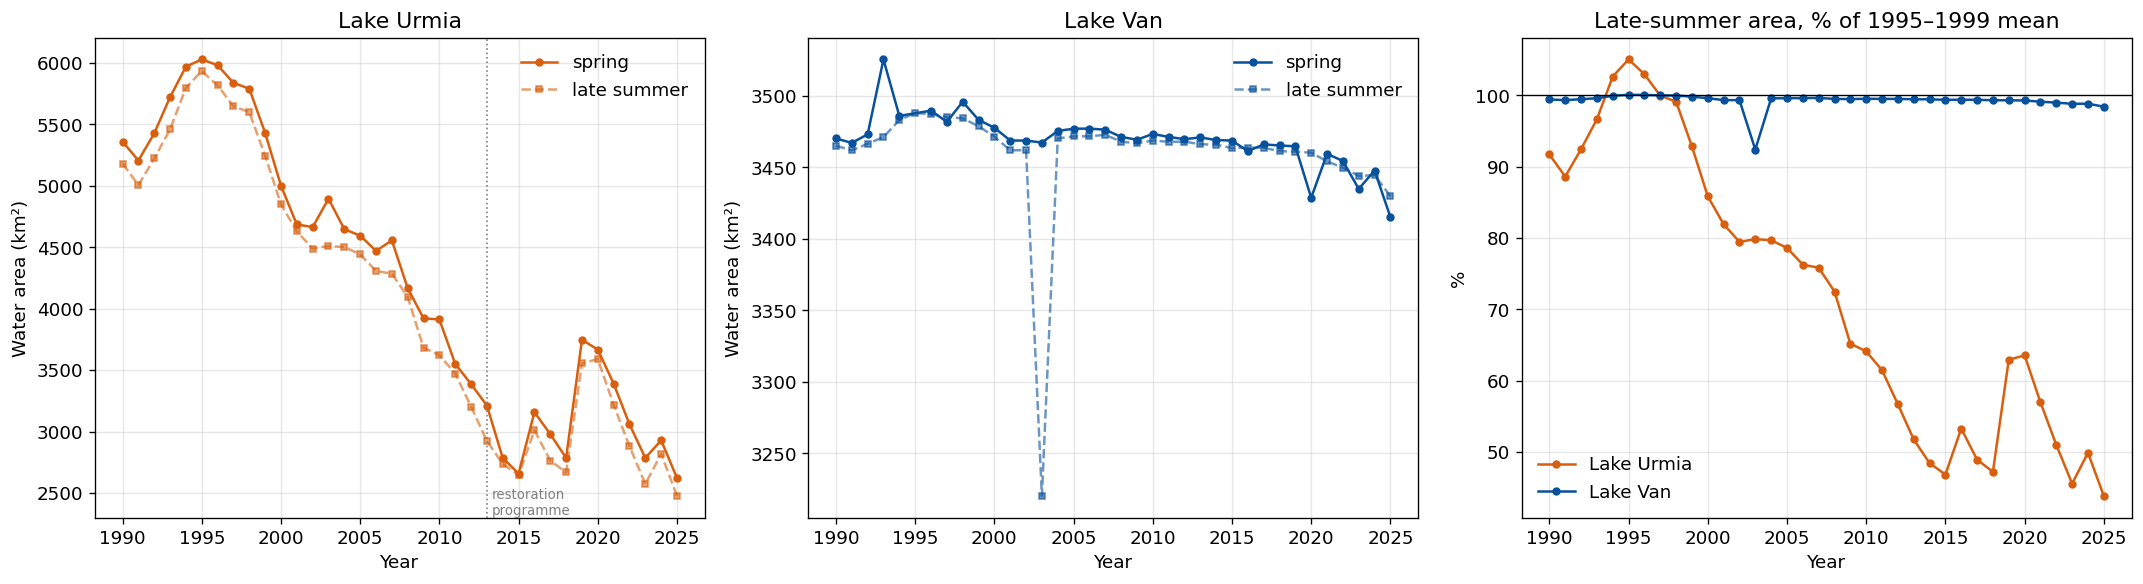

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for ax, name in zip(axes[:2], LAKES):
    for season, style in zip(SEASONS, ["o-", "s--"]):
        g = good[(good.lake == name) & (good.season == season)]
        ax.plot(g["year"], g["water_km2"], style, ms=4, color=LAKES[name]["color"],
                alpha=1 if season == "spring" else 0.6, label=season)
    if name == "Lake Urmia":
        ax.axvline(RESTORATION_START, color="gray", ls=":", lw=1)
        ax.text(RESTORATION_START + 0.3, ax.get_ylim()[0], "restoration\nprogramme", fontsize=8, color="gray", va="bottom")
    ax.set(title=name, xlabel="Year", ylabel="Water area (km²)"); ax.legend(frameon=False); ax.grid(alpha=0.3)

ax = axes[2]
for name in LAKES:
    g = good[(good.lake == name) & (good.season == "late summer")].set_index("year")["water_km2"]
    ref = g.loc[REFERENCE[0]:REFERENCE[1]].mean()
    ax.plot(g.index, 100 * g / ref, "o-", ms=4, color=LAKES[name]["color"], label=name)
ax.axhline(100, color="k", lw=0.8)
ax.set(title=f"Late-summer area, % of {REFERENCE[0]}–{REFERENCE[1]} mean", xlabel="Year", ylabel="%")
ax.legend(frameon=False); ax.grid(alpha=0.3)
fig.tight_layout(); fig.savefig(f"{FIG_DIR}/01_lake_area_comparison.png"); plt.show()

## 7. What the lakes looked like

True-colour Landsat composites (late summer) for three years: the start of the reference period, the year Lake Urmia
was smallest, and the latest year. Saved as images so they show on GitHub.

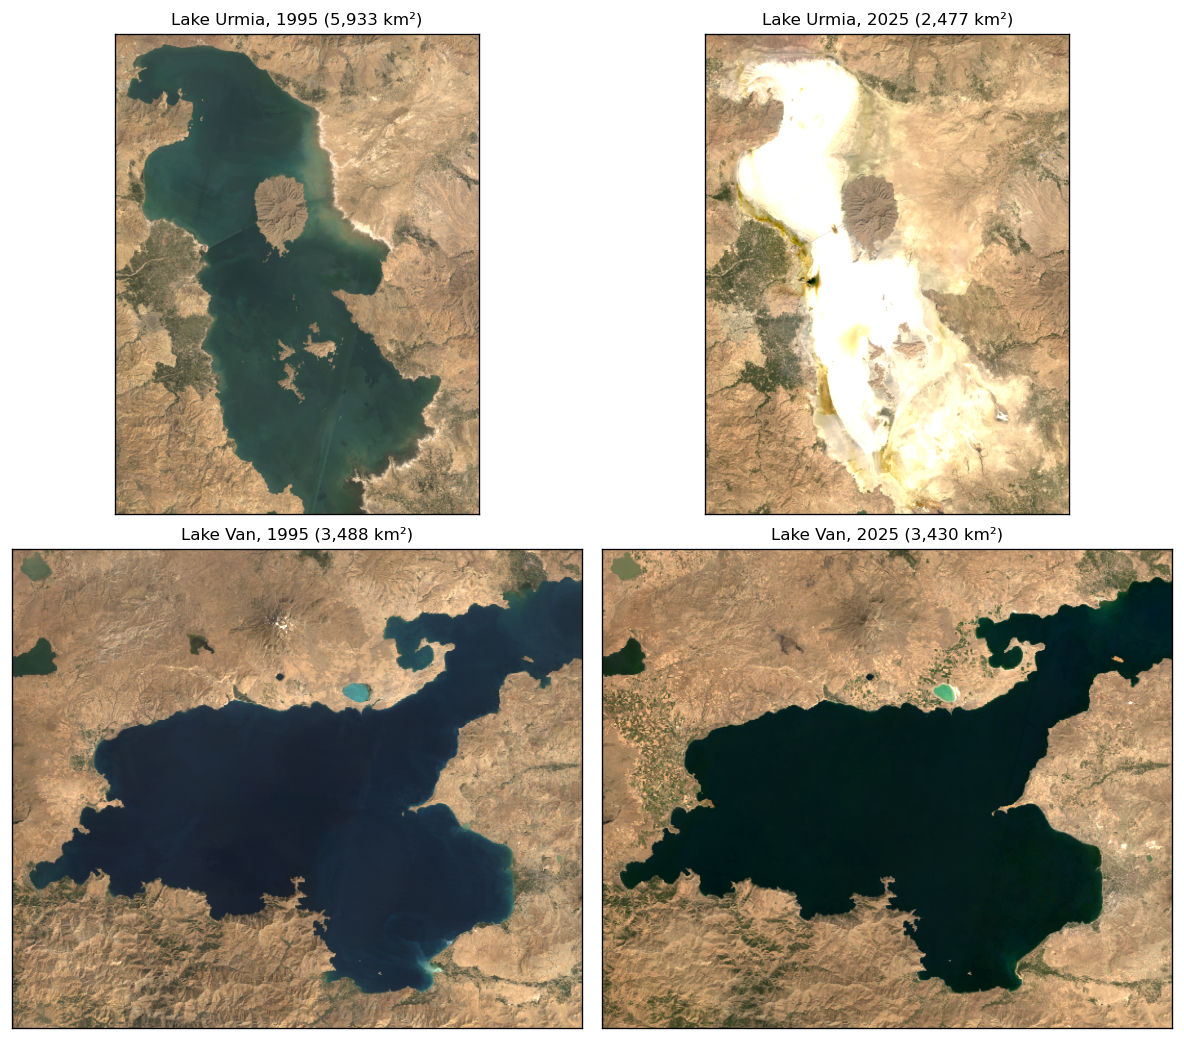

In [8]:
def thumb(key, image, region, dims=700):
    path = f"{MAP_DIR}/{key}.png"
    if os.path.exists(path):
        return np.array(Image.open(path))
    for size in (dims, 500, 350):
        try:
            url = image.getThumbURL({"region": region, "dimensions": size, "crs": "EPSG:4326", "format": "png"})
            resp = requests.get(url, timeout=600); resp.raise_for_status()
            img = Image.open(io.BytesIO(resp.content)); img.save(path)
            return np.array(img)
        except Exception as e:
            reason = getattr(getattr(e, "response", None), "text", "") or str(e)
            print(f"  {key} at {size}px failed: {reason[:100].strip()} - trying smaller")
    return None

urmia_ls = good[(good.lake == "Lake Urmia") & (good.season == "late summer")].set_index("year")["water_km2"]
map_years = sorted({REFERENCE[0] if REFERENCE[0] in urmia_ls.index else int(urmia_ls.index.min()),
                    int(urmia_ls.idxmin()), int(urmia_ls.index.max())})

fig, axes = plt.subplots(len(LAKES), len(map_years), figsize=(5 * len(map_years), 4.4 * len(LAKES)), squeeze=False)
for r, (name, lake) in enumerate(LAKES.items()):
    b = lake["bbox"]
    for col, year in enumerate(map_years):
        comp, _ = season_composite(name, year, SEASONS["late summer"])
        arr = thumb(f"{name.replace(' ', '_')}_{year}",
                    comp.select(["red", "green", "blue"]).visualize(min=0, max=0.3, gamma=1.3), ee.Geometry.Rectangle(b))
        ax = axes[r, col]
        if arr is not None:
            ax.imshow(arr, extent=[b[0], b[2], b[1], b[3]])
        area = good[(good.lake == name) & (good.season == "late summer") & (good.year == year)]["water_km2"]
        ax.set_title(f"{name}, {year}" + (f" ({area.iloc[0]:,.0f} km²)" if len(area) else ""), fontsize=10)
        ax.set_aspect(1 / np.cos(np.radians(np.mean(b[1::2])))); ax.set_xticks([]); ax.set_yticks([])
fig.tight_layout(); fig.savefig(f"{FIG_DIR}/02_lakes_true_colour.png"); plt.show()

## 8. Rain and temperature over each lake's drainage basin

A closed lake responds to everything that happens in its basin, so I average ERA5-Land monthly precipitation and
temperature over the whole basin (all HydroBASINS level-7 sub-basins that drain to the same end point as the lake).
Precipitation is summed over the **water year** (October–September), which ends just before the late-summer area.

Lake Urmia: 435 months
Lake Van: 435 months
Basin areas (km²): {'Lake Urmia': 52200.0, 'Lake Van': 935573.0}


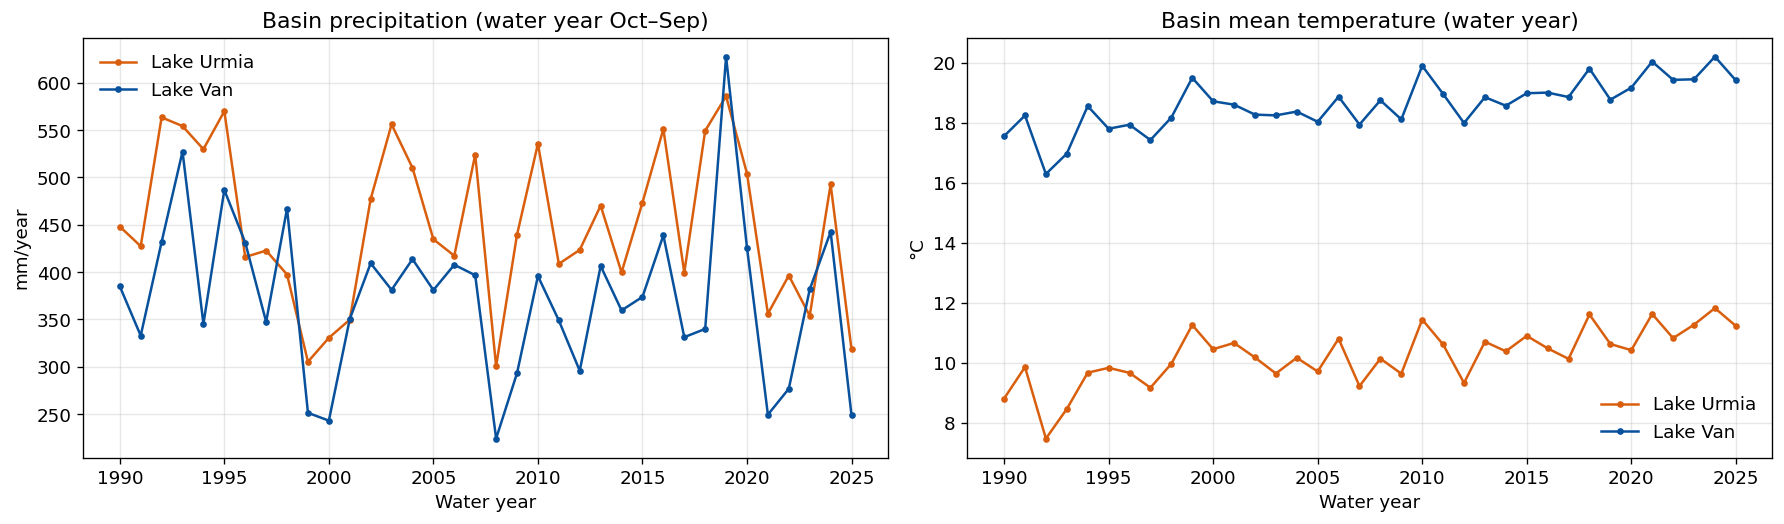

,Years compared,Rain vs. area change (Spearman ρ),p (rain),Temperature vs. area change (Spearman ρ),p (temperature),Basin rain 1995–1999 (mm/yr),Basin rain last 10 years (mm/yr),"Warming, last 10 years vs. reference (°C)"
Lake,,,,,,,,
Lake Urmia,35,0.81,0.0,-0.26,0.13,422.29,450.74,1.03
Lake Van,35,0.60,0.0,-0.36,0.03,396.81,376.29,1.25


In [9]:
CLIMATE_CSV = f"{OUT_DIR}/basin_climate_monthly.csv"
if os.path.exists(CLIMATE_CSV):
    climate = pd.read_csv(CLIMATE_CSV, parse_dates=["date"])
else:
    era5 = ee.ImageCollection("ECMWF/ERA5_LAND/MONTHLY_AGGR").filterDate(f"{START_YEAR - 1}-10-01", f"{END_YEAR + 1}-01-01")
    frames = []
    for name, lake in LAKES.items():
        level7 = ee.FeatureCollection("WWF/HydroSHEDS/v1/Basins/hybas_7")
        main = level7.filterBounds(ee.Geometry.Point(lake["center"])).first().get("MAIN_BAS")
        basin = level7.filter(ee.Filter.eq("MAIN_BAS", main)).geometry()
        def monthly(img):
            vals = img.select(["total_precipitation_sum", "temperature_2m"]).reduceRegion(
                ee.Reducer.mean(), basin, 11132, maxPixels=1e10, tileScale=4)
            return ee.Feature(None, vals).set("date", img.date().format("YYYY-MM-dd"))
        rows = [f["properties"] for f in with_retries(lambda: era5.map(monthly).getInfo())["features"]]
        frames.append(pd.DataFrame(rows).assign(lake=name,
                                                basin_km2=with_retries(lambda: basin.area(1000).divide(1e6).getInfo())))
        print(f"{name}: {len(rows)} months")
    climate = pd.concat(frames, ignore_index=True)
    climate["date"] = pd.to_datetime(climate["date"])
    climate.to_csv(CLIMATE_CSV, index=False)

climate["precip_mm"] = climate["total_precipitation_sum"] * 1000
climate["temp_c"] = climate["temperature_2m"] - 273.15
climate["water_year"] = climate["date"].dt.year + (climate["date"].dt.month >= 10)
yearly_climate = (climate.groupby(["lake", "water_year"])
                         .agg(precip_mm=("precip_mm", "sum"), temp_c=("temp_c", "mean"), months=("precip_mm", "size"))
                         .reset_index().query("months == 12"))
print("Basin areas (km²):", climate.groupby("lake")["basin_km2"].first().round(0).to_dict())

# Does a wet year make the lake bigger by late summer? Compare rain with the change in late-summer area.
rows = []
for name in LAKES:
    ls = good[(good.lake == name) & (good.season == "late summer")].set_index("year")["water_km2"].sort_index()
    change = ls.diff().rename("area_change_km2")
    merged = yearly_climate[yearly_climate.lake == name].set_index("water_year").join(change, how="inner").dropna()
    rho_p, p_p = stats.spearmanr(merged["precip_mm"], merged["area_change_km2"]) if len(merged) > 5 else (np.nan, np.nan)
    rho_t, p_t = stats.spearmanr(merged["temp_c"], merged["area_change_km2"]) if len(merged) > 5 else (np.nan, np.nan)
    pc = yearly_climate[yearly_climate.lake == name].set_index("water_year")
    early = pc.loc[REFERENCE[0]:REFERENCE[1]]
    late = pc.loc[END_YEAR - 9:END_YEAR]
    rows.append({"Lake": name, "Years compared": len(merged),
                 "Rain vs. area change (Spearman ρ)": rho_p, "p (rain)": p_p,
                 "Temperature vs. area change (Spearman ρ)": rho_t, "p (temperature)": p_t,
                 f"Basin rain {REFERENCE[0]}–{REFERENCE[1]} (mm/yr)": early["precip_mm"].mean(),
                 f"Basin rain last 10 years (mm/yr)": late["precip_mm"].mean(),
                 "Warming, last 10 years vs. reference (°C)": late["temp_c"].mean() - early["temp_c"].mean()})
climate_table = pd.DataFrame(rows).set_index("Lake")
climate_table.round(3).to_csv(f"{OUT_DIR}/climate_vs_area.csv")

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 4.5))
for name in LAKES:
    g = yearly_climate[yearly_climate.lake == name]
    ax1.plot(g["water_year"], g["precip_mm"], "o-", ms=3, color=LAKES[name]["color"], label=name)
    ax2.plot(g["water_year"], g["temp_c"], "o-", ms=3, color=LAKES[name]["color"], label=name)
ax1.set(title="Basin precipitation (water year Oct–Sep)", xlabel="Water year", ylabel="mm/year")
ax2.set(title="Basin mean temperature (water year)", xlabel="Water year", ylabel="°C")
for ax in (ax1, ax2):
    ax.legend(frameon=False); ax.grid(alpha=0.3)
fig.tight_layout(); fig.savefig(f"{FIG_DIR}/03_basin_climate.png"); plt.show()
climate_table.round(2)

## 10. Notes

- **Data:** USGS Landsat 5/7/8/9 Collection 2 Level-2; JRC Global Surface Water v1.4 (Pekel et al. 2016); ERA5-Land monthly
  (Muñoz Sabater 2019); HydroSHEDS/HydroBASINS (Lehner & Grill 2013); optional DAHITI altimetry (Schwatke et al. 2015).
- **Lake Urmia is hard to map:** at its lowest, large parts are a few centimetres of brine over salt crust. Bright salt and
  very shallow water can be confused, so the late-summer areas are the least certain; the JRC check shows how much this matters.
- **Lake Van has steep shores:** its area changes little even when its level moves by a metre or more, so small percentage
  changes in area can hide real changes in water volume. That is where altimetry adds the most.
- Landsat 7 images after May 2003 have stripes of missing data; with other sensors in the same season the median fills most of
  them, and seasons where less than `MIN_COVERAGE` of the lake was seen are left out.
- Before about 1999 the Landsat archive for this region has gaps, so some early seasons may be missing.
- ERA5-Land is a model reanalysis at ~9 km; basin averages are good for year-to-year comparison but miss local detail.
- The rain–area relationship cannot separate climate from water use: both basins have irrigation, but on very different scales.